# Quantum 2D Bridges

NicDeclic  
2026-11-23

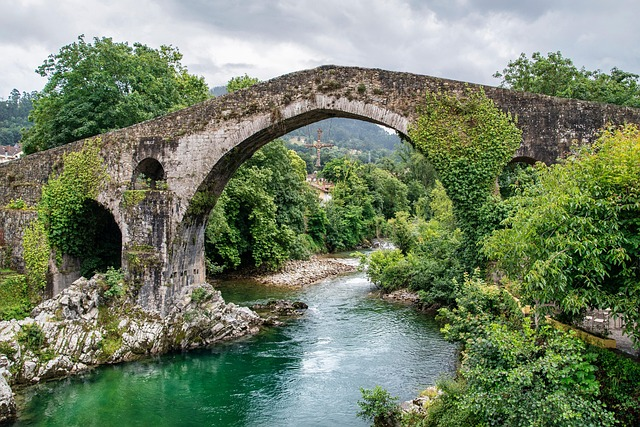

> *“Truth is not complex. It is our journey toward it that is.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicdeclic/quantum-molecular-computing/blob/main/posts/quantum-chemistry/index.ipynb)

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

Very often in molecular processor design, circuit topologies are
inherently non-planar: two independent data lines need to cross, or an
interconnect must bridge across the interior of a closed molecular ring.

One natural solution is to deploy three-dimensional architectures using
vertical **$\pi$-stacking couplers** (layering conjugated rings on top
of one another).

However, when exploring an emerging technology, simplicity is paramount:
keeping the entire fabric strictly **two-dimensional** avoids complex
multi-layer synthesis.

*But is a strictly 2D signal crossing even theoretically possible
without physical short-circuits?*

------------------------------------------------------------------------

## The Cellular Automata Precedent: The 3-XOR Trick

In the domain of 2D cellular automata, this wire-crossing problem was
solved long ago. It relies on the famous **3-XOR SWAP trick**:

$$\begin{aligned}
A_1 &= A \oplus B \\
B'  &= B \oplus A_1 = B \oplus (A \oplus B) = \mathbf{A} \\
A'  &= A_1 \oplus B' = (A \oplus B) \oplus A = \mathbf{B}
\end{aligned}$$

By cascading three XOR operations, the identities of two variables are
swapped in-place without requiring any temporary intermediate storage:

``` python
# Initialize schematic drawing for the 3-XOR SWAP circuit
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # Vertical coordinates for the two data rails
    y_a = 2.75
    y_b = 0.0
    x_in = 0.0

    # ==========================================
    # 1. Place the 3 XOR Gates in Cascade
    # ==========================================
    # Stage 1: XOR on line A (A1 = A XOR B)
    xor1 = d.add(logic.Xor().right().at((3.0, y_a + 0.25)))

    # Stage 2: XOR on line B (B' = B XOR A1 = A)
    xor2 = d.add(logic.Xor().right().at((6.5, y_b)))

    # Stage 3: XOR on line A (A' = A1 XOR B' = B)
    xor3 = d.add(logic.Xor().right().at((10.0, y_a)))

    # ==========================================
    # 2. Stage 1 Connections (A1 = A XOR B)
    # ==========================================
    # Input A straight to xor1 in1
    d.add(elm.Line().at((x_in, y_a + 0.5)).to(xor1.in1).label("$A$", loc="left"))

    # Input B line
    d.add(elm.Line().at((x_in, y_b - 0.25)).to((1.5, y_b - 0.25)).label("$B$", loc="left"))
    d.add(elm.Dot().at((1.5, y_b - 0.25)))
    
    # Tap B up into xor1 in2
    d.add(elm.Wire("|-").at((1.5, y_b - 0.25)).to(xor1.in2))

    # ==========================================
    # 3. Stage 2 Connections (B' = B XOR A1)
    # ==========================================
    # Continue line B to xor2 in2
    d.add(elm.Line().at((1.5, y_b - 0.25)).to(xor2.in2))

    # Line A1 from xor1 out towards xor3
    d.add(elm.Line().at(xor1.out).to((5.0, y_a)))
    d.add(elm.Dot().at((5.0, y_a + 0.25)))

    # Tap A1 down into xor2 in1
    d.add(elm.Wire("|-").at((5.0, y_a + 0.25)).to(xor2.in1))

    # ==========================================
    # 4. Stage 3 Connections (A' = A1 XOR B')
    # ==========================================
    # Connect A1 line to xor3 in1
    d.add(elm.Line().at((5.0, y_a + 0.25)).to(xor3.in1))

    # Line B' from xor2 out towards output
    d.add(elm.Line().at(xor2.out).to((8.5, y_b)))
    d.add(elm.Dot().at((8.5, y_b)))

    # Tap B' up into xor3 in2
    d.add(elm.Wire("|-").at((8.5, y_b)).to(xor3.in2))

    # Final Output B' (which carries the original value of A)
    d.add(elm.Line().at((8.5, y_b)).to((12.5, y_b)).label("$A$", loc="right"))

    # Final Output A' (which carries the original value of B)
    d.add(elm.Line().at(xor3.out).to((12.5, y_a)).label("$B$", loc="right"))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

## The Protobit Analog

Remarkably, there exists a direct, native molecular equivalent for
protobits that achieves planar signal crossing.

Here is the **Octagonal 2D Bridge**:

To a classical intuition, watching this happen looks almost like magic:
**two independent logic signals intersect within the same physical
carbon ring without interfering with one another.**

This is neither quantum tunneling nor long-distance teleportation.
Rather, the delocalized $\pi$-electrons behave like **non-interacting
optical solitons (or transverse photon modes)**. The signals pass
straight through each other as smoothly as two intersecting laser beams
crossing in free space.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Octogonal Bridge")

# Add atoms
c1 = mol.add_atom(x=-0.5, y=1.0)
c2 = mol.add_atom(x=0.5, y=1.0)
c3 = mol.add_atom(x=-1.0, y=0.5)
c4 = mol.add_atom(x=-0.4, y=0.3)
c5 = mol.add_atom(x=0.4, y=0.3)
c6 = mol.add_atom(x=1.0, y=0.5)
c7 = mol.add_atom(x=-1.0, y=-0.5)
c8 = mol.add_atom(x=-0.4, y=-0.3)
c9 = mol.add_atom(x=0.4, y=-0.3)
c10 = mol.add_atom(x=1.0, y=-0.5)
c11 = mol.add_atom(x=-0.5, y=-1.0)
c12 = mol.add_atom(x=0.5, y=-1.0)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single", label="B")
b2 = mol.add_bond(c3, c1, order="single")
b3 = mol.add_bond(c4, c1, order="single")
b4 = mol.add_bond(c5, c2, order="single")
b5 = mol.add_bond(c6, c2, order="single")
b6 = mol.add_bond(c3, c4, order="single")
b7 = mol.add_bond(c4, c5, order="single")
b8 = mol.add_bond(c5, c6, order="single")
b9 = mol.add_bond(c3, c7, order="single", label="A")
b10 = mol.add_bond(c6, c10, order="single", label="A")
b11 = mol.add_bond(c7, c8, order="single")
b12 = mol.add_bond(c8, c9, order="single")
b13 = mol.add_bond(c9, c10, order="single")
b14 = mol.add_bond(c7, c11, order="single")
b15 = mol.add_bond(c8, c11, order="single")
b16 = mol.add_bond(c9, c12, order="single")
b17 = mol.add_bond(c10, c12, order="single")
b18 = mol.add_bond(c11, c12, order="single", label="B")

coupler1 = mol.add_coupler(b7, b12)

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>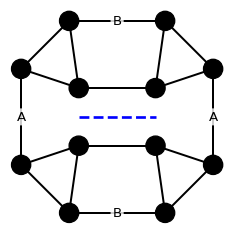</p>
</div></td>
</tr>
</tbody>
</table>

Now, let us examine the global resonance structures. As the simulation
below confirms, **whatever logical state enters along path $A$ or path
$B$ exits cleanly at its respective opposite terminal**:

``` python
all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>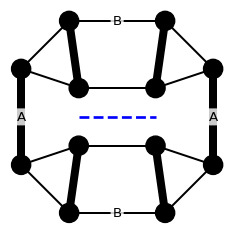</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>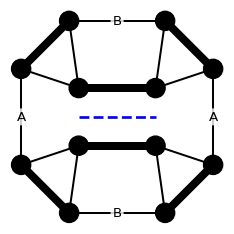</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>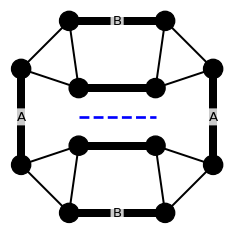</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>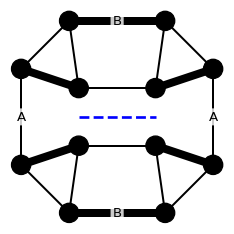</p>
</div></td>
</tr>
</tbody>
</table>

Ironically, an urban cartographer looking at the skeletal drawing of the
octagonal molecule would instinctively assume they are looking at the
standard map symbol of a **bridge crossing a river**:

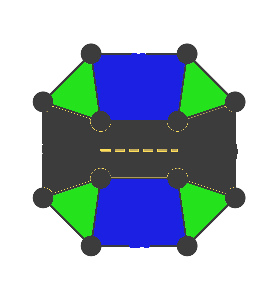

Yet the physical mechanism is entirely unique: there is no upper deck
and no lower tunnel. The crossing happens **within the exact same single
atomic plane**.

------------------------------------------------------------------------

## Hexagonal Grids: The Dodecagonal Bridge

While the Octagonal Bridge integrates naturally into square or
rectangular Manhattan-style circuit layouts, hexagonal lattices (such as
graphene sheets) demand higher rotational symmetry.

For these architectures, we can engineer a **Dodecagonal 2D Bridge**. In
addition to performing planar crossing, its expanded geometry natively
supports **fan-in and fan-out routing** across terminals:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Dodecagonal Bridge")

# Add atoms
c1 = mol.add_atom(x=-0.3, y=1.0)
c2 = mol.add_atom(x=0.3, y=1.0)
c3 = mol.add_atom(x=-0.6, y=0.7)
c4 = mol.add_atom(x=0.6, y=0.7)
c5 = mol.add_atom(x=-0.3, y=0.4)
c6 = mol.add_atom(x=0.3, y=0.4)
c7 = mol.add_atom(x=-0.9, y=0.2)
c8 = mol.add_atom(x=0.9, y=0.2)
c9 = mol.add_atom(x=-0.9, y=-0.2)
c10 = mol.add_atom(x=0.9, y=-0.2)
c11 = mol.add_atom(x=-0.3, y=-0.4)
c12 = mol.add_atom(x=0.3, y=-0.4)
c13 = mol.add_atom(x=-0.6, y=-0.7)
c14 = mol.add_atom(x=0.6, y=-0.7)
c15 = mol.add_atom(x=-0.3, y=-1.0)
c16 = mol.add_atom(x=0.3, y=-1.0)
c17 = mol.add_atom(x=-0.5, y=0.0)
c18 = mol.add_atom(x=0.5, y=0.0)


# Add bonds
b1 = mol.add_bond(c1, c2, order="single", label="B")
b2 = mol.add_bond(c1, c3, order="single")
b3 = mol.add_bond(c1, c5, order="single")
b4 = mol.add_bond(c2, c6, order="single")
b5 = mol.add_bond(c2, c4, order="single")
b6 = mol.add_bond(c3, c5, order="single")
b7 = mol.add_bond(c6, c4, order="single")
b8 = mol.add_bond(c5, c6, order="single")
b9 = mol.add_bond(c3, c7, order="single", label="A")
b10 = mol.add_bond(c4, c8, order="single", label="A")
b11 = mol.add_bond(c7, c9, order="single")
b12 = mol.add_bond(c7, c17, order="single")
b13 = mol.add_bond(c8, c18, order="single")
b14 = mol.add_bond(c8, c10, order="single")
b15 = mol.add_bond(c17, c18, order="single")
b16 = mol.add_bond(c17, c9, order="single")
b17 = mol.add_bond(c18, c10, order="single")
b18 = mol.add_bond(c9, c13, order="single", label="B")
b19 = mol.add_bond(c10, c14, order="single", label="B")
b20 = mol.add_bond(c13, c11, order="single")
b21 = mol.add_bond(c13, c15, order="single")
b22 = mol.add_bond(c12, c16, order="single")
b23 = mol.add_bond(c12, c14, order="single")
b24 = mol.add_bond(c11, c15, order="single")
b25 = mol.add_bond(c14, c16, order="single")
b26 = mol.add_bond(c15, c16, order="single", label="A")
b27 = mol.add_bond(c11, c12, order="single")

coupler1 = mol.add_coupler(b8, b15)
coupler2 = mol.add_coupler(b27, b15)

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>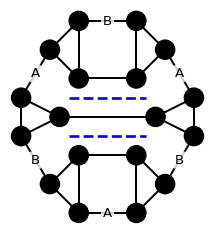</p>
</div></td>
</tr>
</tbody>
</table>

Here are its resonance states, confirming that signals introduced at
either boundary $A$ or $B$ propagate strictly to their targeted outputs
without cross-contamination:

``` python
all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>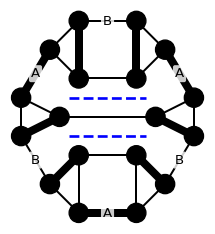</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>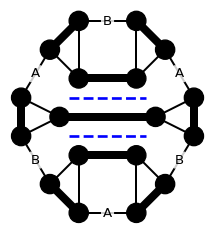</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>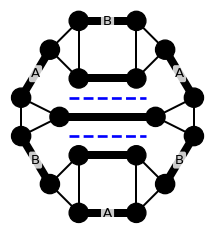</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>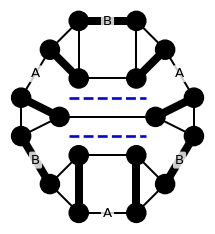</p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

### The Architectural Verdict

Through these planar bridges, **every bond of a complex carbon network
becomes topologically routable without leaving the 2D plane.**

While multi-layer 3D fabrication offers denser volumetric integration,
2D planar bridges provide a massive manufacturing advantage: they allow
an entire quantum molecular processor to be synthesized on a single,
atomically thin monolayer sheet.

------------------------------------------------------------------------

## 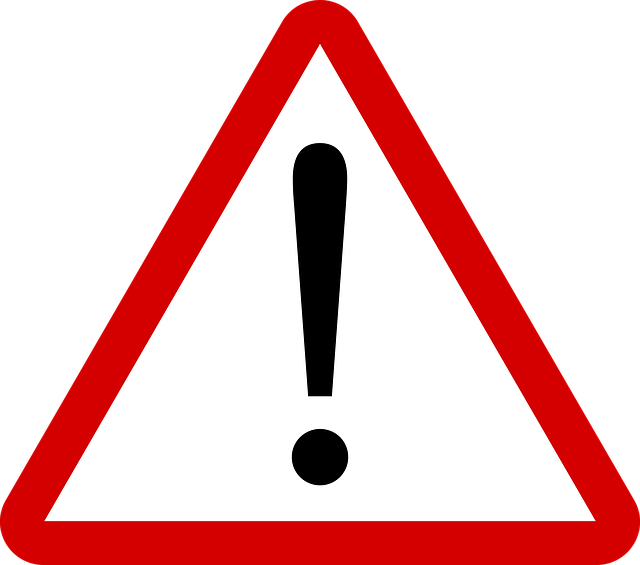 Speculations & Wild Thoughts

- The Coupler Mystery

Across all my explorations, **I have never succeeded in designing a
working 2D bridge that functions without at least one Coupler.**

The non-contact inductive coupling seems strictly necessary for the two
paths to slide past one another.

I strongly suspect that a coupler-free 2D bridge may be a topological
impossibility within pure $sp^2$ carbon chemistry.

However, if you happen to discover a valid 2D bridge topology that
operates cleanly without any couplers, **please reach out in the
comments below!** Such a discovery would provide profound new clues
regarding the ultimate boundary limits of Protobits.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Quantum Set Theory”](../../posts/quantum-set-theory/index.html)**